In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.17.0


In [102]:
data = pd.read_csv(r"/home/pvg/Desktop/dataset/creditcard.csv")

print("Dataset Shape:", data.shape)
data.head()


Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [103]:
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [104]:
data = data.drop_duplicates()

print("Dataset Shape after removing duplicates:", data.shape)


Dataset Shape after removing duplicates: (283726, 31)


In [105]:
print(data["Class"].value_counts())


Class
0    283253
1       473
Name: count, dtype: int64


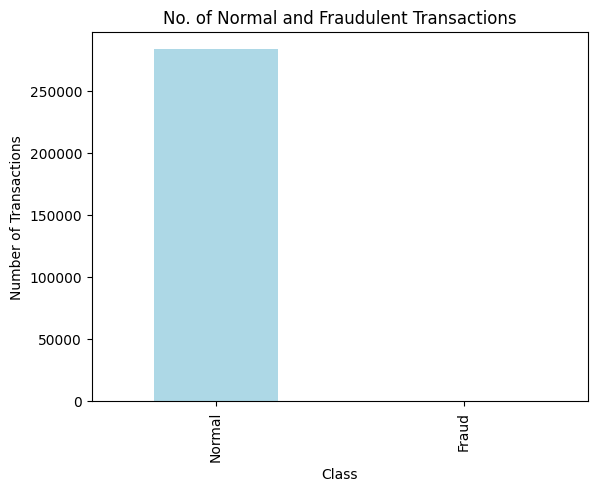

In [145]:
data["Class"].value_counts().plot(
    kind="bar",
    color=["lightblue", "red"]
)

plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.title("No. of Normal and Fraudulent Transactions")
plt.xticks(
    [0,1],
    ["Normal", "Fraud"]
    
)

plt.show()


In [107]:
X = data.drop("Class", axis=1)
y = data["Class"]

print("Features:", X.shape)
print("Target:", y.shape)


Features: (283726, 30)
Target: (283726,)


In [108]:
data = data.drop_duplicates()

print("Dataset shape after removing duplicates:")
print(data.shape)


Dataset shape after removing duplicates:
(283726, 31)


In [109]:
X = data.drop("Class", axis=1)
y = data["Class"]


In [110]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)



X_train: (226980, 30)
X_test : (56746, 30)


In [111]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape :", X_test_scaled.shape)


Training data shape: (226980, 30)
Testing data shape : (56746, 30)


In [112]:
X_train_scaled = X_train_scaled.astype("float32")
X_test_scaled = X_test_scaled.astype("float32")


In [113]:
X_train_normal = X_train_scaled[
    y_train.values == 0
]

print(
    "Normal transactions used for training:",
    X_train_normal.shape
)


Normal transactions used for training: (226597, 30)


In [114]:
input_features = X_train_normal.shape[1]

autoencoder = Sequential([

    # Input layer
    Input(shape=(input_features,)),

    # Encoder
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),

    # Decoder
    Dense(16, activation="relu"),
    Dense(32, activation="relu"),
    Dense(64, activation="relu"),

    # Output layer
    Dense(input_features, activation="linear")
])

autoencoder.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 30)             │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,478 (37.02 KB)

 Trainable params: 9,478 (37.02 KB)

 Non-trainable params: 0 (0.00 B)

In [115]:
autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("Autoencoder compiled successfully.")


Autoencoder compiled successfully.


In [116]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,

    epochs=5,

    batch_size=20000,

    validation_split=0.20,

    shuffle=True,

    verbose=1
)


Epoch 1/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.9542 - mae: 0.6572 - val_loss: 0.9389 - val_mae: 0.6548
Epoch 2/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.9644 - mae: 0.6540 - val_loss: 0.9159 - val_mae: 0.6503
Epoch 3/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.9207 - mae: 0.6482 - val_loss: 0.8846 - val_mae: 0.6445
Epoch 4/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.9036 - mae: 0.6422 - val_loss: 0.8483 - val_mae: 0.6337
Epoch 5/5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.8441 - mae: 0.6295 - val_loss: 0.8096 - val_mae: 0.6196


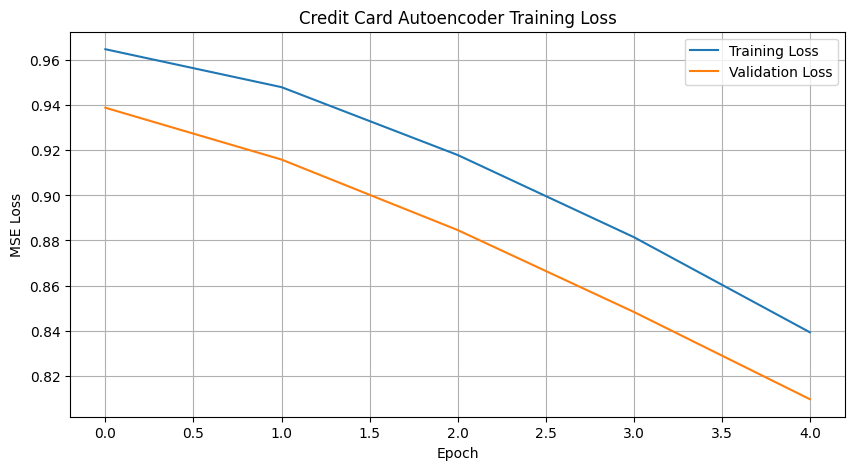

In [117]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "Credit Card Autoencoder Training Loss"
)

plt.legend()
plt.grid()

plt.show()


In [118]:
X_train_reconstructed = autoencoder.predict(
    X_train_normal,
    batch_size=256,
    verbose=0
)

print(
    "Original shape:",
    X_train_normal.shape
)

print(
    "Reconstructed shape:",
    X_train_reconstructed.shape
)


Original shape: (226597, 30)
Reconstructed shape: (226597, 30)


In [119]:
normal_error = np.mean(
    np.square(
        X_train_normal -
        X_train_reconstructed
    ),
    axis=1
)

print("Normal reconstruction error:")
print(normal_error[:10])


Normal reconstruction error:
[1.292427   0.6551841  0.21452285 0.37952903 0.35253945 0.86799276
 0.6771511  0.8810904  0.42732483 0.5126955 ]


In [120]:
threshold = np.percentile(
    normal_error,
    95
)

print(
    "Anomaly Threshold:",
    threshold
)


Anomaly Threshold: 1.5901106119155872


In [121]:
X_test_reconstructed = autoencoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print(
    "Test reconstructed shape:",
    X_test_reconstructed.shape
)


Test reconstructed shape: (56746, 30)


In [122]:
test_error = np.mean(
    np.square(
        X_test_scaled -
        X_test_reconstructed
    ),
    axis=1
)

print("First 10 test errors:")
print(test_error[:10])


First 10 test errors:
[0.9058686  1.5798324  0.76366895 0.4322851  1.1892077  0.30094278
 1.3677828  0.33547628 0.57697207 0.607589  ]


In [123]:
y_pred = (
    test_error > threshold
).astype(int)

print("Predicted classes:")
print(y_pred[:20])


Predicted classes:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [124]:
results = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Reconstruction_Error": test_error,
    "Predicted_Class": y_pred
})

results.head(20)


,Actual_Class,Reconstruction_Error,Predicted_Class
0,0,0.905869,0
1,0,1.579832,0
2,0,0.763669,0
3,0,0.432285,0
4,0,1.189208,0
5,0,0.300943,0
6,0,1.367783,0
7,0,0.335476,0
8,0,0.576972,0
9,0,0.607589,0


In [125]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)


Accuracy: 0.9500581538786875


In [126]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)


[[53837  2819]
 [   15    75]]


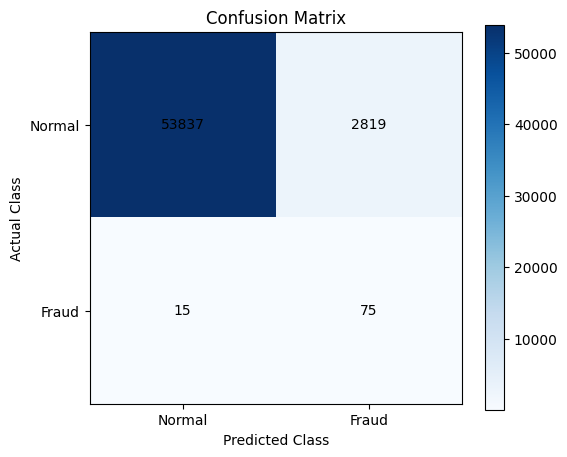

In [127]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm,
    cmap="Blues"
)

plt.colorbar()

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Confusion Matrix")

plt.xticks(
    [0, 1],
    ["Normal", "Fraud"]
)

plt.yticks(
    [0, 1],
    ["Normal", "Fraud"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()


In [128]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Fraud"
        ]
    )
)


              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     56656
       Fraud       0.03      0.83      0.05        90

    accuracy                           0.95     56746
   macro avg       0.51      0.89      0.51     56746
weighted avg       1.00      0.95      0.97     56746



In [129]:
fraud_transactions = results[
    results["Predicted_Class"] == 1
]

print(
    "Number of detected anomalies:",
    len(fraud_transactions)
)

fraud_transactions.head(20)


Number of detected anomalies: 2894


,Actual_Class,Reconstruction_Error,Predicted_Class
27,0,2.910777,1
35,0,32.207989,1
44,0,3.045564,1
84,0,4.132450,1
117,0,1.763229,1
128,0,3.166484,1
141,0,31.401909,1
208,0,2.487495,1
213,0,1.606190,1
260,0,2.189623,1
